# NYC Airbnb prices and subway access

An extension of the original DSCI 510 project using its October 2025 listing snapshot, MTA subway station locations, and ACS 2019–2023 tract context. The primary analysis excludes hospitality listings using the recorded room and property types; a separate full-catalog analysis retains them.

This notebook reads the pipeline's saved local inputs and results. It makes no network calls. It distinguishes descriptive price differences, adjusted observational associations, and out-of-fold prediction performance. Full source definitions and limitations are in [Data sources](../docs/DATA_SOURCES.md).

## Load the saved analysis

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'results' / 'metrics.json').is_file()
             and (p / 'src' / 'nyc_airbnb').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or notebooks directory after running the pipeline.')

metrics = json.loads((ROOT / 'results' / 'metrics.json').read_text(encoding='utf-8'))
quality = metrics.get('quality', metrics)
model_metrics = pd.read_csv(ROOT / 'results' / 'tables' / 'model_metrics.csv')
coefficients = pd.read_csv(ROOT / 'results' / 'tables' / 'coefficient_estimates.csv')
boroughs = pd.read_csv(ROOT / 'results' / 'tables' / 'borough_summary.csv')
segments = pd.read_csv(ROOT / 'results' / 'tables' / 'distance_segments.csv')
listings = pd.read_csv(ROOT / 'data' / 'processed' / 'listings.csv',
                      usecols=['id', 'price', 'latitude', 'longitude', 'dist_km', 'median_household_income'],
                      dtype={'id': str})
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_columns', 12)


## Results at a glance

In [2]:
within_500 = (listings['dist_km'] <= 0.5).mean() * 100
summary = [
    f"**{len(listings):,} positive-priced listings in the primary sample**, after NYC tract matching and the stated hospitality exclusion.",
    f"Median advertised price: **${listings['price'].median():,.0f}/night**.",
    f"**{within_500:.1f}%** are within 500 m of a subway station in straight-line distance.",
]
spatial_rows = model_metrics[model_metrics['validation'].astype(str).str.contains('spatial', case=False)]
if not spatial_rows.empty:
    best = spatial_rows.sort_values('mae_usd').iloc[0]
    summary.append(f"Lowest spatial-validation MAE among the evaluated candidates: "
                   f"**${best['mae_usd']:,.2f}/night** ({str(best['model']).replace('_', ' ')}).")
if isinstance(quality.get('raw_listings'), (int, float)):
    summary.append(f"The source contained {int(quality['raw_listings']):,} listing rows; "
                   "missing/invalid prices and spatial eligibility affect the usable sample.")
display(Markdown((chr(10) * 2).join(summary)))


**20,308 positive-priced listings in the primary sample**, after NYC tract matching and the stated hospitality exclusion.

Median advertised price: **$150/night**.

**71.6%** are within 500 m of a subway station in straight-line distance.

Lowest spatial-validation MAE among the evaluated candidates: **$79.22/night** (Full without transit).

The source contained 36,111 listing rows; missing/invalid prices and spatial eligibility affect the usable sample.

## Context and methods

The outcome is the advertised nightly listing price. The primary population excludes records with room type `Hotel room` or property types matching `hotel|hostel|resort` (case-insensitive). This uses recorded listing taxonomy, rather than verifying a property's legal status. No price-tail trimming is applied to the primary population. Subway distances use a local metric projection and station coordinates; Staten Island Railway is excluded. Census tract income and population are lagged area characteristics.

Prediction models are compared using random and spatial-block out-of-fold predictions. Preprocessing is fitted within each training fold. Dollar errors and log1p-price R² answer different questions, so both are retained. The separate inference regressions use ln(price), report their own sample sizes and confidence intervals, and estimate conditional associations.

### Assumptions and scope

- The historical snapshot describes available listing records, rather than a census of completed stays.
- Positive-priced eligible records define this analysis population. Missing prices can create selection bias.
- A 500 m straight-line threshold is an access proxy. Listing location anonymization and station entrance locations limit its precision.
- Spatial validation holds out the stated geographic groups. It does not demonstrate future-period or host-independent performance.
- Property, neighborhood, and host factors can confound subway-price associations. No coefficient is interpreted as a causal transit effect.

## Prediction performance in the primary sample

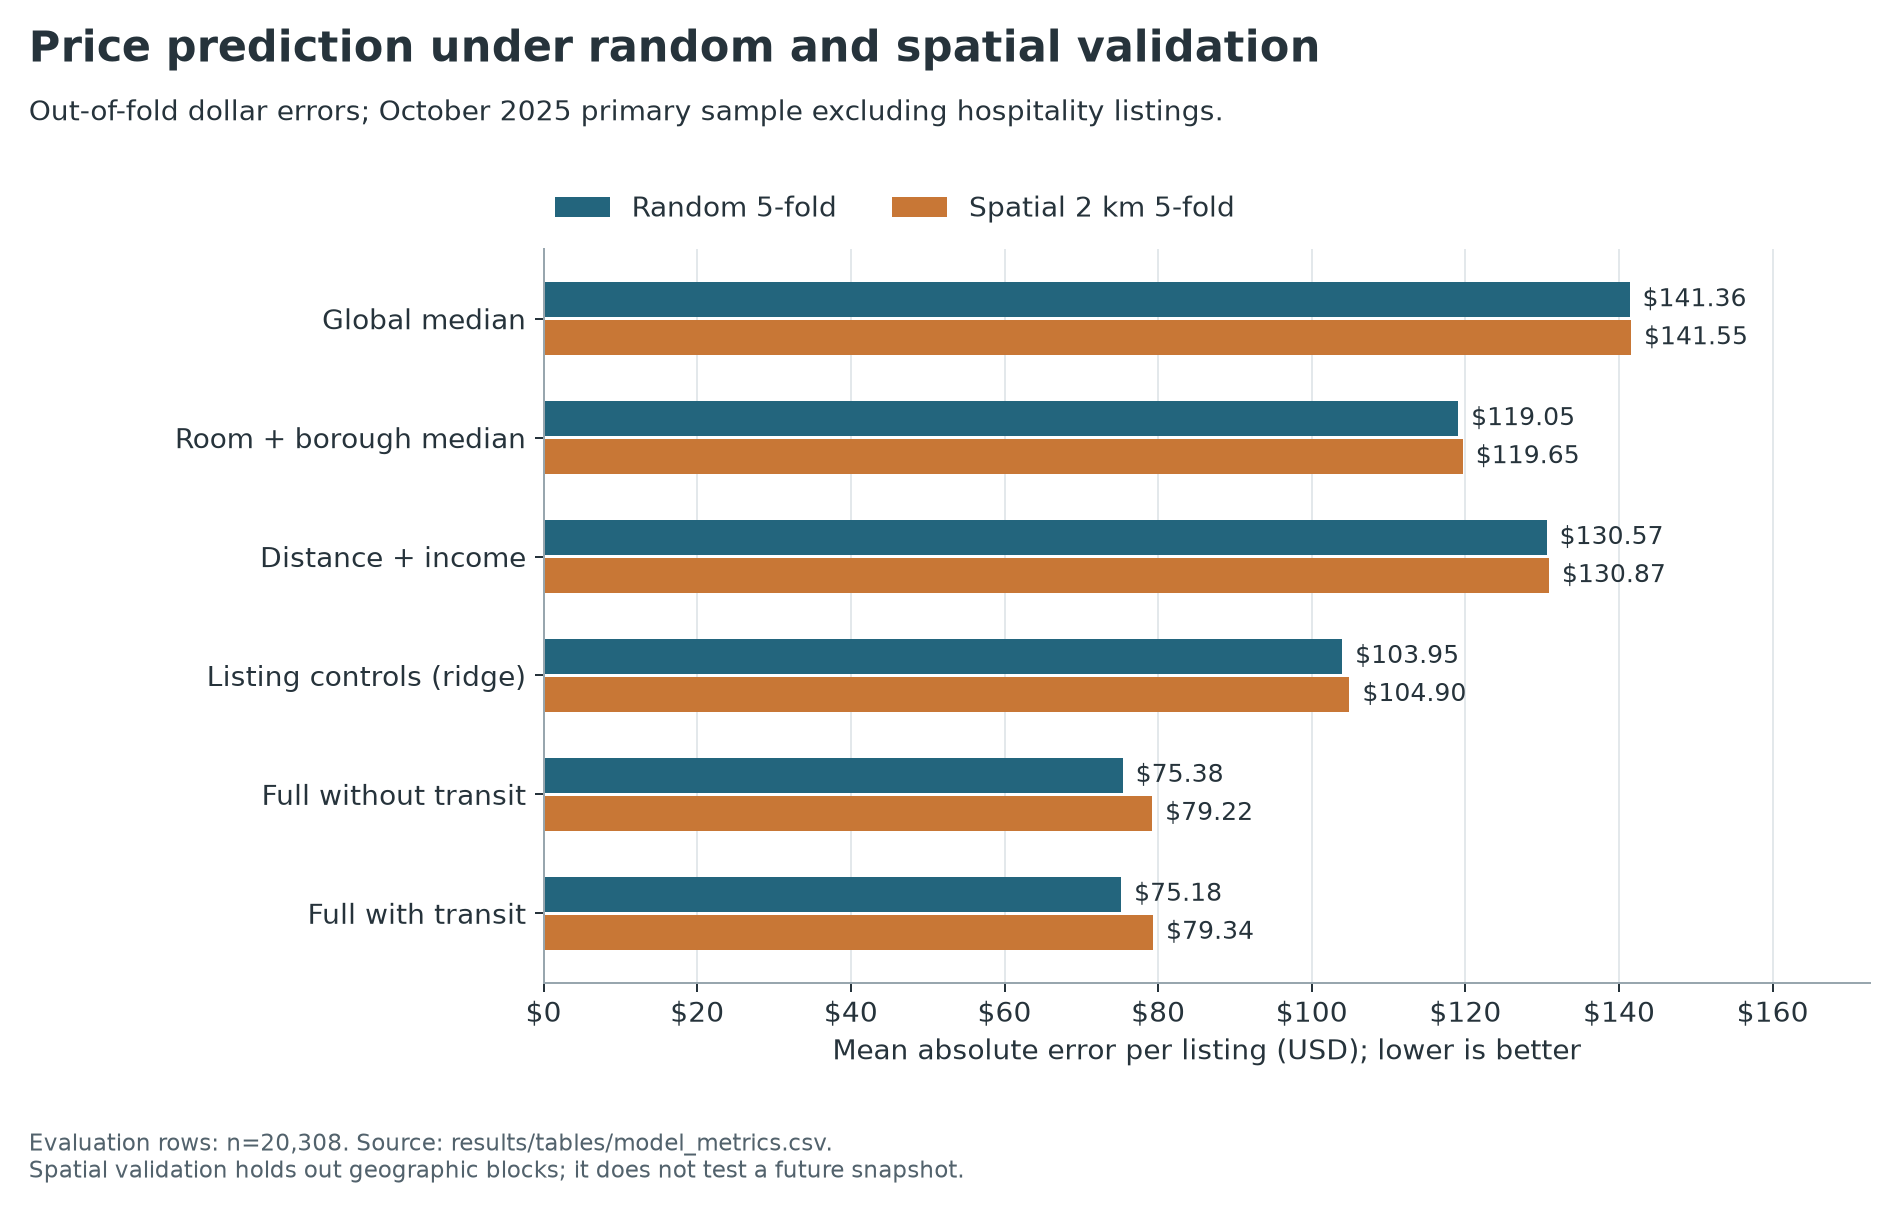

,validation,model,n,mae_usd,rmse_usd,median_ae_usd,r2_log
0,Random 5-fold,Global median,20308,141.36,592.83,75.00,-0.001
1,Random 5-fold,Room + borough median,20308,119.05,581.50,50.50,0.380
2,Random 5-fold,Distance + income,20308,130.57,584.94,66.70,0.174
3,Random 5-fold,Listing controls (ridge),20308,103.95,562.56,44.63,0.557
4,Random 5-fold,Full without transit,20308,75.38,539.98,29.62,0.764
5,Random 5-fold,Full with transit,20308,75.18,540.06,29.29,0.765
6,Spatial 2 km 5-fold,Global median,20308,141.55,593.11,75.00,-0.006
7,Spatial 2 km 5-fold,Room + borough median,20308,119.65,581.64,51.00,0.372
8,Spatial 2 km 5-fold,Distance + income,20308,130.87,585.08,66.73,0.170
9,Spatial 2 km 5-fold,Listing controls (ridge),20308,104.90,563.99,45.41,0.548


In [3]:
display(Image(filename=str(ROOT / 'figures' / 'model_validation.png')))
display(model_metrics.round({'mae_usd': 2, 'rmse_usd': 2, 'median_ae_usd': 2, 'r2_log': 3}))


Dollar MAE is the average absolute nightly-price error across held-out predictions. RMSE gives larger errors more weight. Median absolute error describes the typical listing. Compare models on the same validation population; a random/spatial gap measures sensitivity to the partition, rather than an automatic deployment guarantee.

### Full-catalog sensitivity

The source includes hospitality records with advertised prices near $40,000–50,000 per night. These are suspected data/price anomalies, not verified luxury-market observations. They are retained without correction in a separate full-catalog benchmark so the population choice remains inspectable. Its errors should not be compared as if measured on the primary sample.

In [4]:
full_catalog_path = ROOT / 'results' / 'tables' / 'full_catalog' / 'model_metrics.csv'
if full_catalog_path.exists():
    full_catalog = pd.read_csv(full_catalog_path)
    display(full_catalog.round({'mae_usd': 2, 'rmse_usd': 2, 'median_ae_usd': 2, 'r2_log': 3}))
else:
    display(Markdown('Full-catalog sensitivity table is unavailable in this run; do not infer its performance.'))


,validation,model,n,mae_usd,rmse_usd,median_ae_usd,r2_log
0,Random 5-fold,Global median,21326,590.03,4511.42,80.00,-0.009
1,Random 5-fold,Room + borough median,21326,311.19,2556.27,57.00,0.453
2,Random 5-fold,Distance + income,21326,577.26,4495.92,73.66,0.169
3,Random 5-fold,Listing controls (ridge),21326,435.82,3416.83,47.65,0.661
4,Random 5-fold,Full without transit,21326,297.62,2538.72,31.85,0.818
5,Random 5-fold,Full with transit,21326,294.56,2510.25,31.80,0.818
6,Spatial 2 km 5-fold,Global median,21326,590.43,4511.36,81.00,-0.013
7,Spatial 2 km 5-fold,Room + borough median,21326,345.50,2828.48,58.00,0.431
8,Spatial 2 km 5-fold,Distance + income,21326,577.84,4496.33,74.35,0.161
9,Spatial 2 km 5-fold,Listing controls (ridge),21326,441.90,3467.11,48.60,0.652


## Subway distance after controls

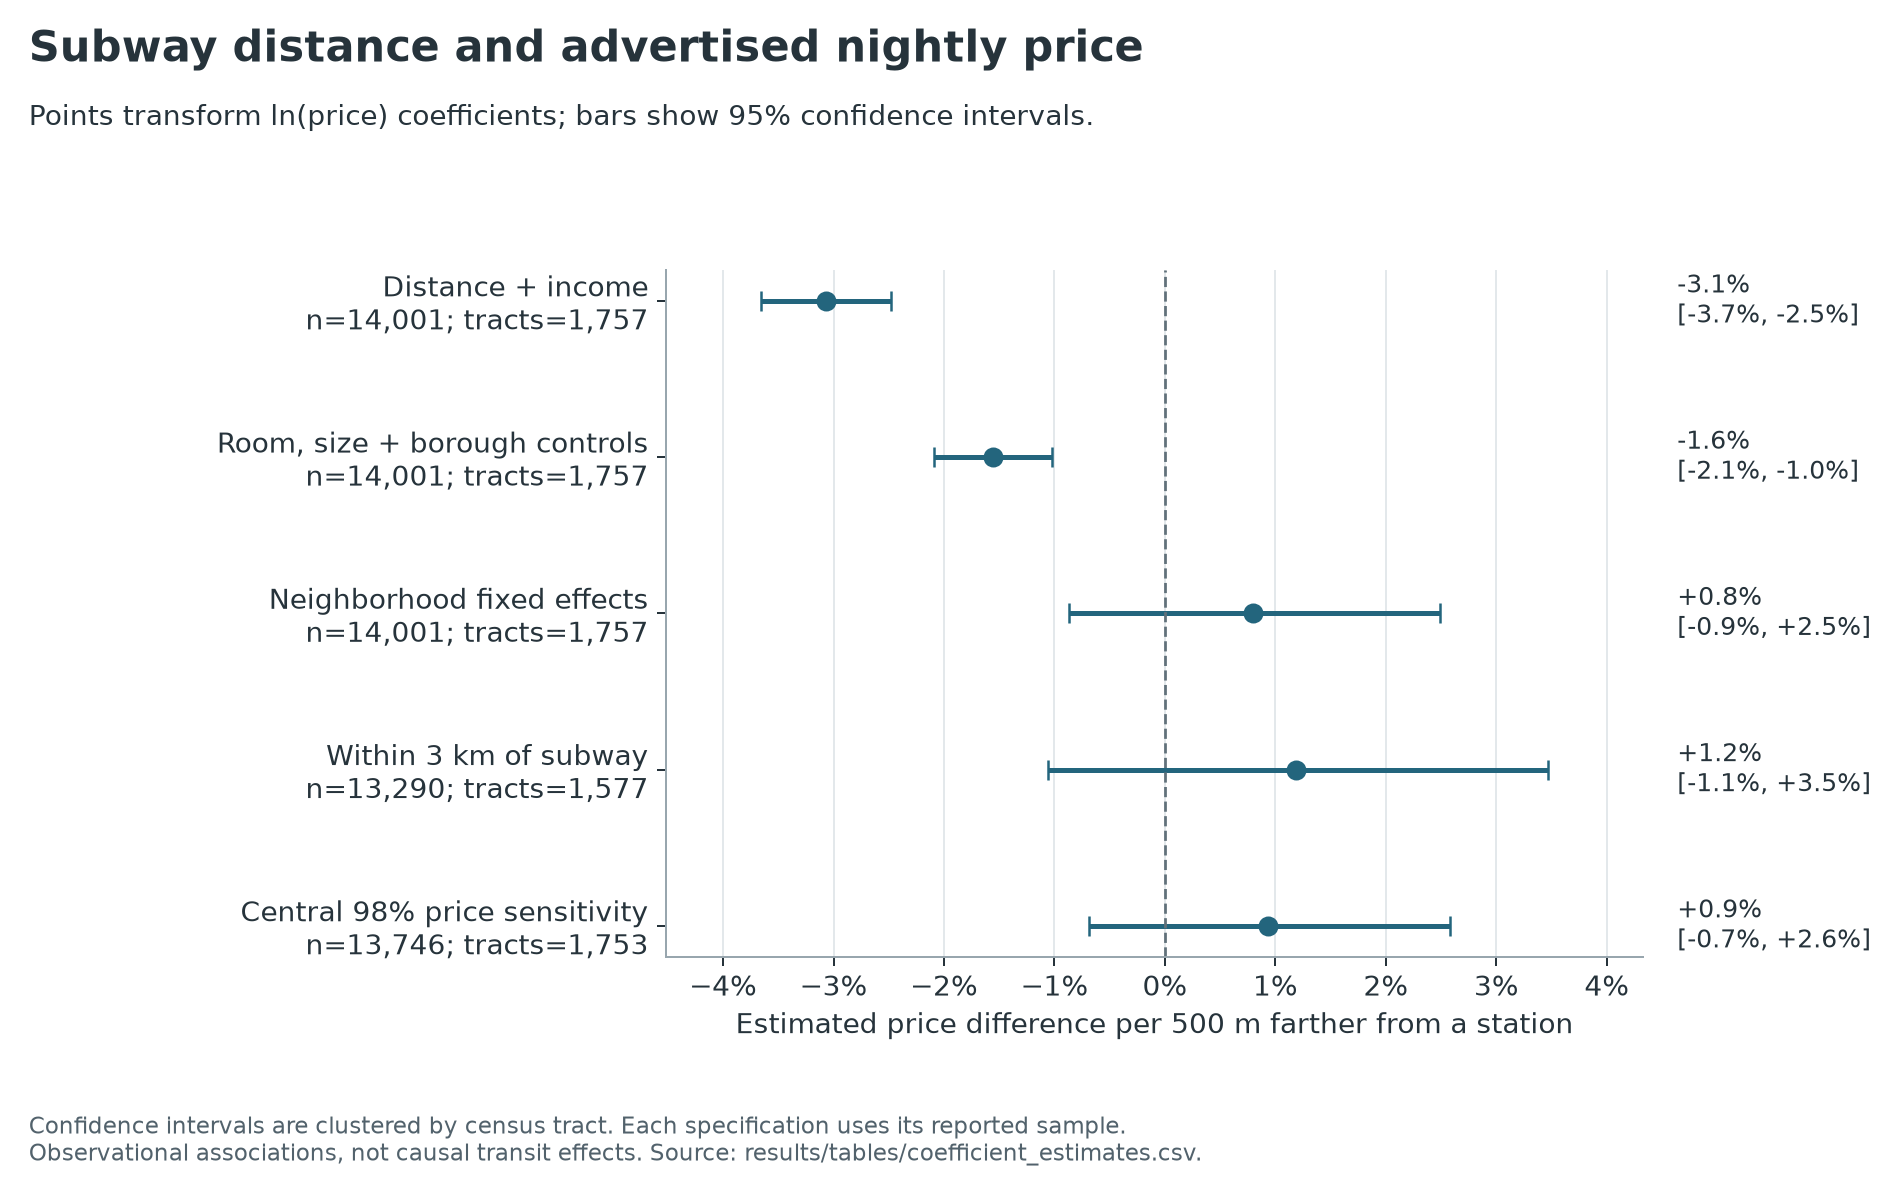

,specification,n,tract_clusters,percent_per_500m,ci_lower_pct,ci_upper_pct
0,Distance + income,14001,1757,-3.07,-3.66,-2.48
1,"Room, size + borough controls",14001,1757,-1.56,-2.09,-1.02
2,Neighborhood fixed effects,14001,1757,0.80,-0.87,2.49
3,Within 3 km of subway,13290,1577,1.18,-1.06,3.47
4,Central 98% price sensitivity,13746,1753,0.93,-0.69,2.58


In [5]:
display(Image(filename=str(ROOT / 'figures' / 'subway_association.png')))
columns = ['specification', 'n', 'tract_clusters', 'percent_per_500m', 'ci_lower_pct', 'ci_upper_pct']
display(coefficients[columns].round(2))


The inference regressions use ln(price). The percentage scale is `100 × (exp(0.5 × coefficient_per_km) − 1)`: the modeled relative price difference for 500 m farther from a station, holding the included controls constant. This transformation describes a geometric-price association, not a dollar change in the arithmetic mean. Intervals use tract-clustered regression uncertainty. The first three specifications use the same complete-case sample, so their differences reflect controls rather than a changing sample. An interval spanning zero supports uncertainty about the sign under that specification.

## Price differences within room types

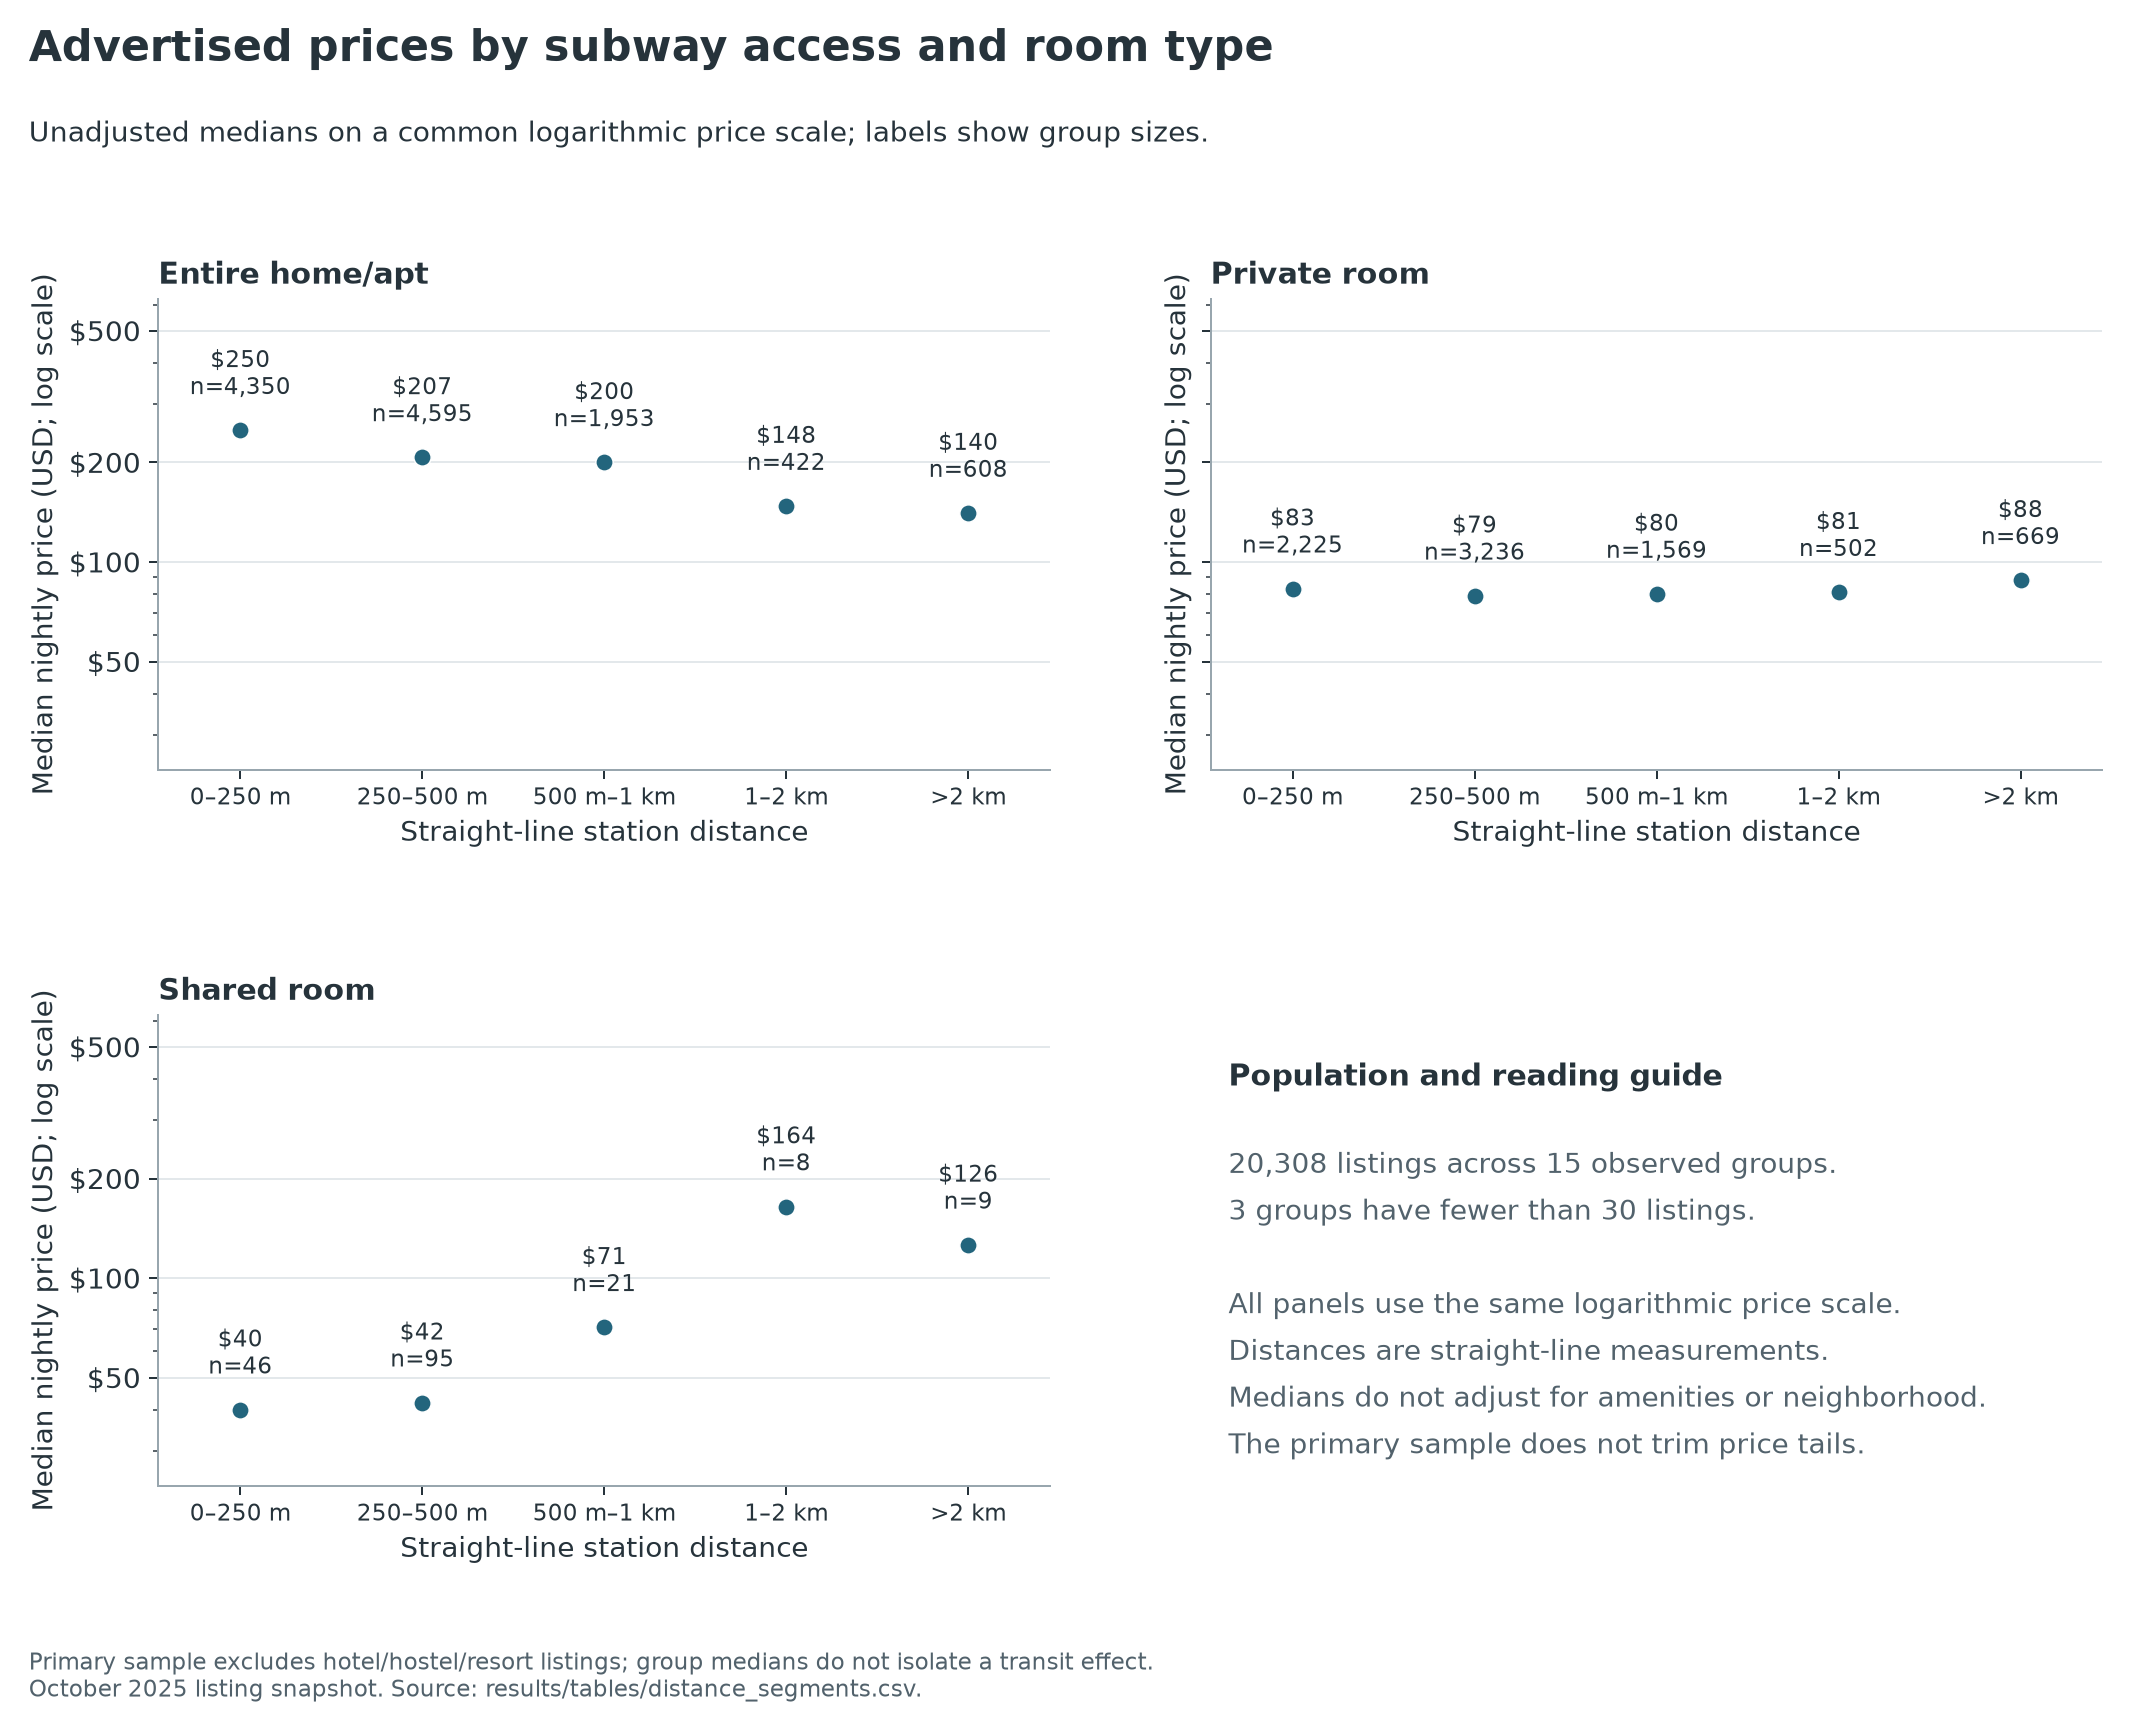

,room_type,distance_band,n,median_price
0,Entire home/apt,0–250 m,4350,250.0
1,Entire home/apt,250–500 m,4595,207.0
2,Entire home/apt,500 m–1 km,1953,200.0
3,Entire home/apt,1–2 km,422,147.5
4,Entire home/apt,>2 km,608,140.5
5,Private room,0–250 m,2225,83.0
6,Private room,250–500 m,3236,79.0
7,Private room,500 m–1 km,1569,80.0
8,Private room,1–2 km,502,81.0
9,Private room,>2 km,669,88.0


In [6]:
display(Image(filename=str(ROOT / 'figures' / 'distance_by_room_type.png')))
display(segments.round({'median_price': 2}).head(20))


These medians describe the primary population. The number of listings is displayed because groups can have very different sample sizes. Room-type separation addresses one major source of mixing, while amenities and neighborhood differences remain. All panels share a logarithmic price axis, and retained price tails are not silently clipped.

## Geographic coverage and accessibility

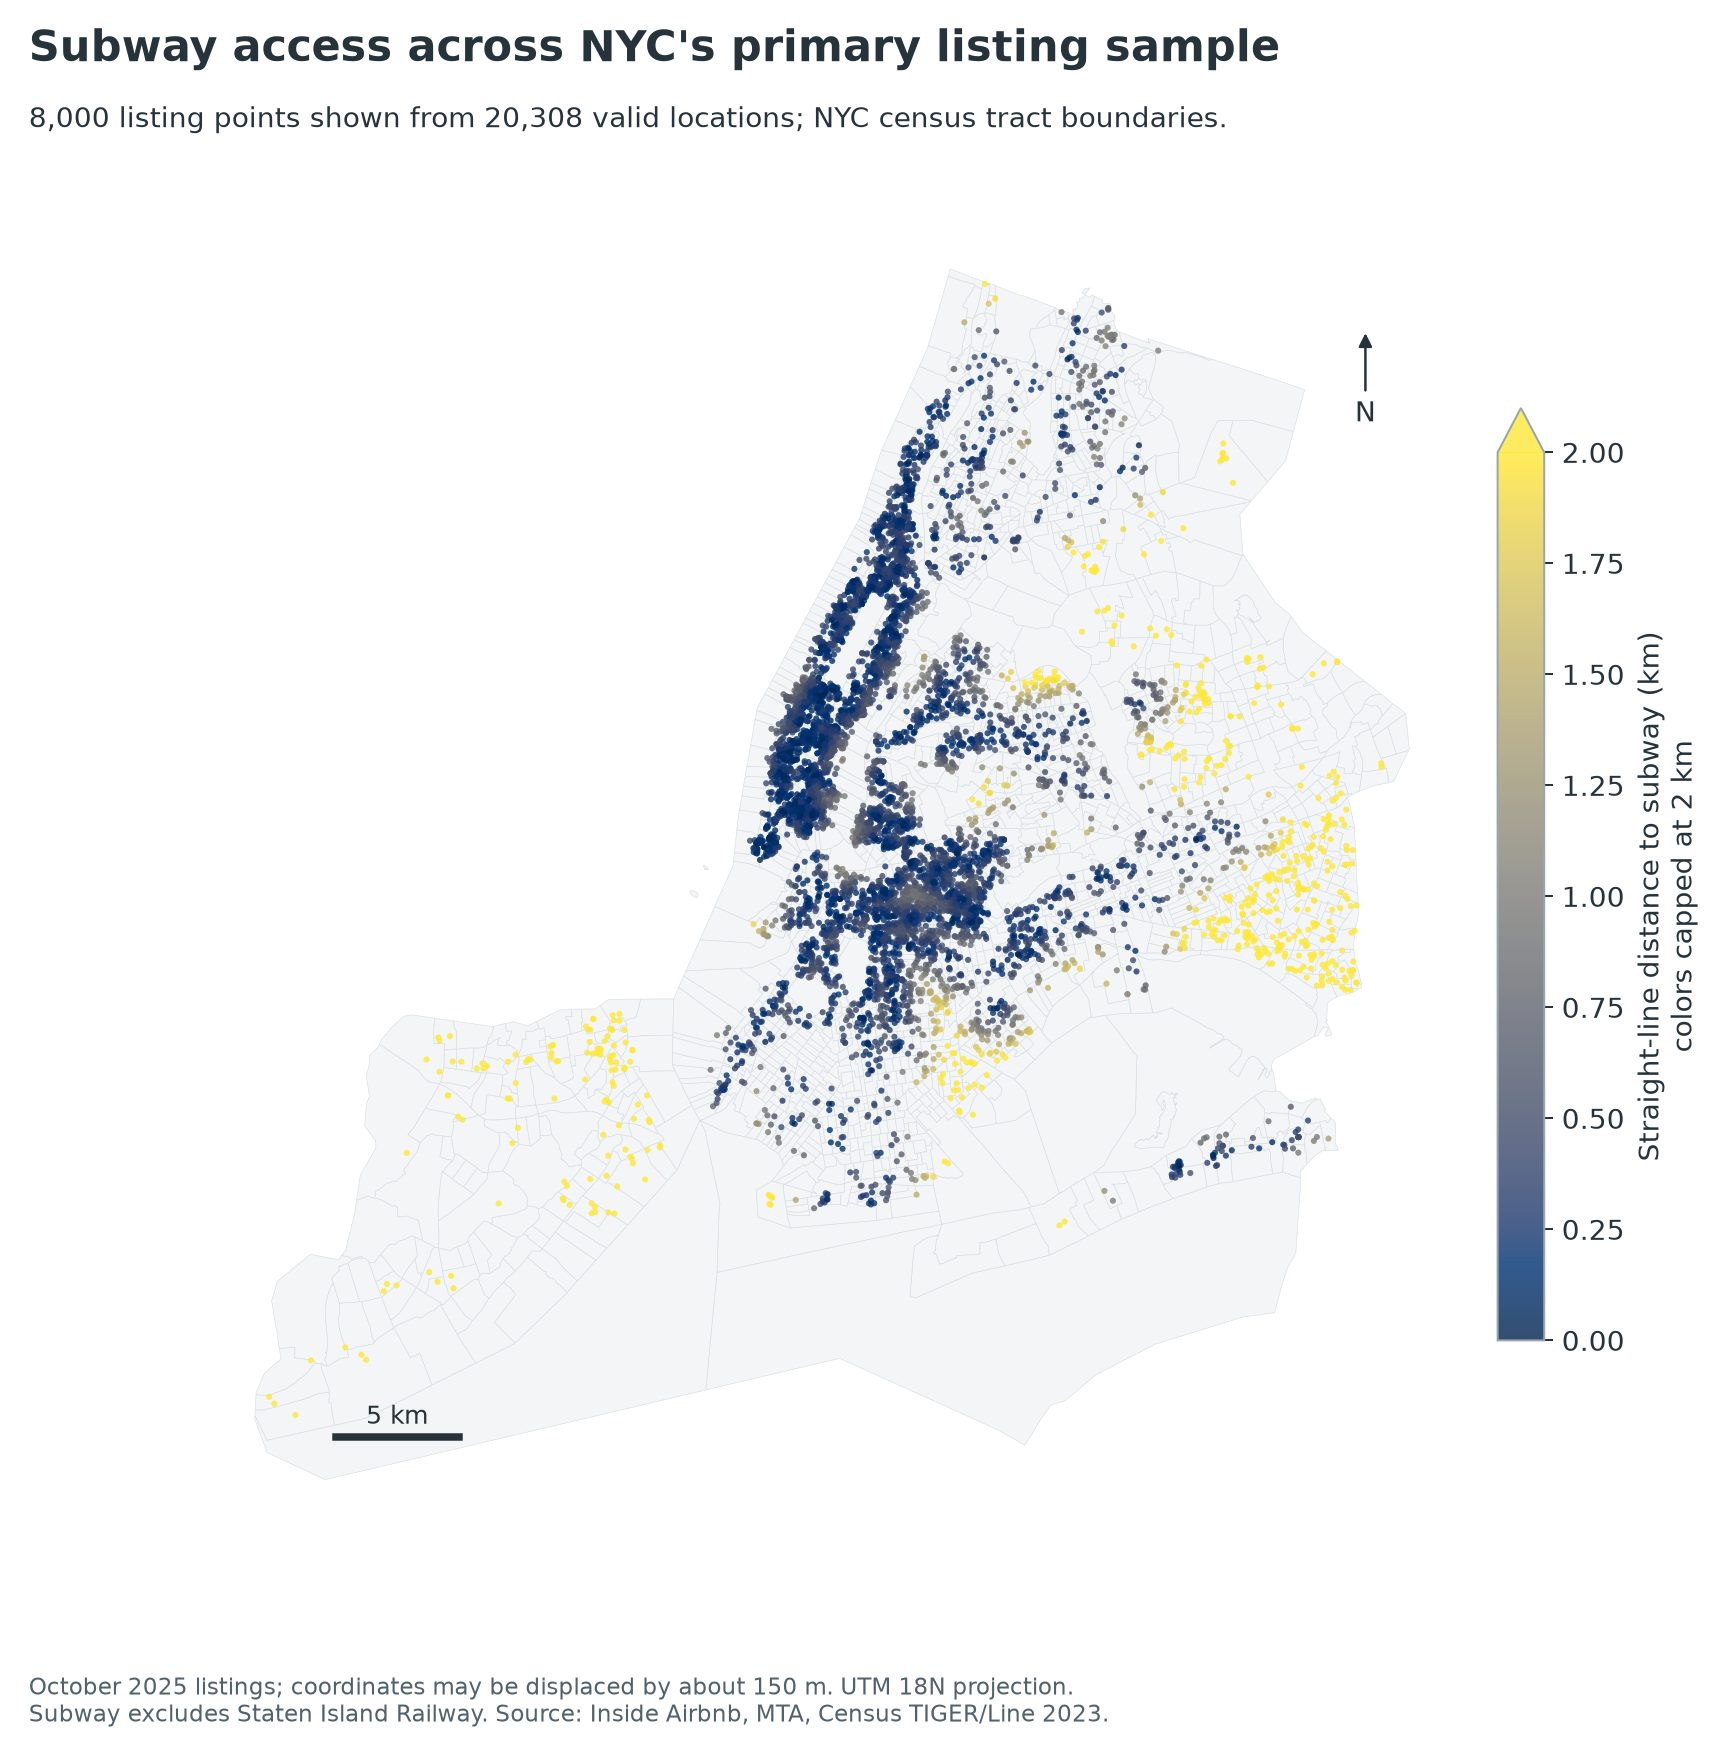

,borough,n,median_price,median_distance_m,within_500m_pct
0,Bronx,824,94.0,446.0,56.1
1,Brooklyn,7418,130.0,356.0,71.1
2,Manhattan,8489,214.0,269.0,88.5
3,Queens,3266,101.0,694.0,39.8
4,Staten Island,311,99.0,6192.0,0.0


In [7]:
display(Image(filename=str(ROOT / 'figures' / 'listing_geography.png')))
display(boroughs.round({'median_price': 2, 'within_500m_pct': 1, 'median_distance_m': 0}))


[Open the interactive geographic map](../results/nyc_airbnb_map.html) to inspect the seeded listing sample and optional subway/tract-income layers. Map popups use the original WGS84 latitude and longitude. Base tiles and interactive-map JavaScript require internet access; all four figures above remain portable notebook image outputs.

Staten Island's large distance to the subway should be interpreted with the explicit exclusion of Staten Island Railway. Low station distance alone does not measure access to jobs, service frequency, entrances, or travel time.

## Data checks and frozen input hashes

In [8]:
assert listings['id'].is_unique, 'Listing IDs must be unique'
assert np.isfinite(listings['price']).all() and (listings['price'] > 0).all()
assert listings['latitude'].between(-90, 90).all()
assert listings['longitude'].between(-180, 180).all()
assert np.isfinite(listings['dist_km']).all() and (listings['dist_km'] >= 0).all()
assert model_metrics['n'].eq(len(listings)).all(), 'Model metrics and primary listing population differ'
if isinstance(quality.get('primary_listing_count'), (int, float)):
    assert len(listings) == int(quality['primary_listing_count'])
elif isinstance(quality.get('analysis_listings'), (int, float)):
    assert len(listings) == int(quality['analysis_listings'])
assert (coefficients['ci_lower_pct'] <= coefficients['percent_per_500m']).all()
assert (coefficients['ci_upper_pct'] >= coefficients['percent_per_500m']).all()

quality_keys = ['raw_listings', 'missing_or_invalid_price', 'nonpositive_price',
                'duplicate_listing_ids_removed', 'unmatched_nyc_tract_listings',
                'priced_spatial_listings', 'hospitality_excluded', 'primary_listing_count',
                'analysis_listings', 'listings_missing_income', 'unique_station_locations']
checks = [{'check': key.replace('_', ' '), 'value': quality[key]}
          for key in quality_keys if key in quality]
display(pd.DataFrame(checks))

manifest = quality.get('source_manifest', {})
if not manifest:
    manifest_path = ROOT / 'data' / 'raw' / 'manifest.json'
    manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path.exists() else {}
sources = manifest.get('sources', {})
hashes = [{'source': key, 'filename': record.get('filename'), 'sha256': record.get('sha256')}
          for key, record in sources.items()]
display(pd.DataFrame(hashes))
print('Notebook arithmetic and input checks passed; source definitions remain in docs/DATA_SOURCES.md.')


,check,value
0,raw listings,36111
1,missing or invalid price,14783
2,nonpositive price,0
3,duplicate listing ids removed,0
4,unmatched nyc tract listings,2
5,priced spatial listings,21326
6,hospitality excluded,1018
7,primary listing count,20308
8,analysis listings,21326
9,listings missing income,317


,source,filename,sha256
0,airbnb,listings.csv.gz,a50efc7b11ef0a0786e38787ae2d4f47af1009943a1049...
1,subway,subway.csv,4f10d7730b4dfe1737cb54426adccb8396346eceec2be9...
2,income,acs_income_2023.dat,c9007017b7bb29ba758c77612ec9a4a0b897a4ed931d52...
3,population,acs_population_2023.dat,24ae3f523b4c54332ce0a71ba534569685a8a729056f97...
4,tracts,tl_2023_36_tract.zip,010dfd8893c8a2a6482c7a0420b0113a8c0a0029137d0f...


Notebook arithmetic and input checks passed; source definitions remain in docs/DATA_SOURCES.md.


## Written interpretation

In [9]:
interpretation = ROOT / 'docs' / 'RESULTS.md'
if interpretation.exists():
    display(Markdown(interpretation.read_text(encoding='utf-8')))
else:
    display(Markdown('Read the executed tables and intervals above together. Predictive evaluation and '
                     'conditional association are separate results; neither establishes a causal subway premium.'))


# Executed findings

Results generated from the source hashes in `results/source_manifest.json`. Primary sample: October 2025 NYC listings excluding recorded hotel, hostel and resort products. All finite positive prices are retained. This is an observational portfolio study, not a deployment or causal evaluation.

## Sample and data quality

| Step | Listings |
| --- | ---: |
| Original source | 36,111 |
| Missing/invalid prices | 14,783 |
| Unique positive-price records | 21,328 |
| Outside/unmatched NYC tract | 2 |
| Priced spatial catalog | 21,326 |
| Hospitality category exclusions | 1,018 |
| Primary non-hotel sample | 20,308 |

The original catalog's hotel-room median is $40,000/night, with substantial masses at $40,000 and $50,000. Just 234 listings above $5,000, 1.10% of the catalog, account for 66.77% of summed asking prices. This sum is a tail diagnostic, not revenue. The source does not prove a cents conversion or justify changing those rates. Hospitality has a median minimum stay of 1 night, compared with 30 nights in the primary sample. Accommodation-product scope is preferable to an arbitrary price cap; hotel-labelled private rooms are also excluded. Remaining extreme residential asks are retained and reflected in RMSE.

## Predictive comparison

| Model | Random MAE ($/night) | Spatial MAE ($/night) | Spatial median AE ($) | Spatial log1p-price R² |
| --- | ---: | ---: | ---: | ---: |
| Global median | 141.36 | 141.55 | 75.00 | -0.006 |
| Room + borough median | 119.05 | 119.65 | 51.00 | 0.372 |
| Distance + income | 130.57 | 130.87 | 66.73 | 0.170 |
| Listing controls (ridge) | 103.95 | 104.90 | 45.41 | 0.548 |
| Full without transit | 75.38 | 79.22 | 31.32 | 0.742 |
| Full with transit | 75.18 | 79.34 | 31.72 | 0.743 |

Every row uses 20,308 held-out predictions, one per listing per validation design. All six candidates share the same folds. The strongest spatial MAE candidate, **Full without transit**, reduces error by **33.8%** against the room/borough median. Its median absolute error is **$31.32**, while RMSE **$545.23** reflects tail failures. R² is on log1p price, not raw dollars. Exponentiating a fitted log mean does not produce an unbiased expected dollar price.

Transit distance and station count add no spatial-MAE benefit beyond coordinates, property features and tract context. The tiny log-R² difference is not evidence of useful business lift. No confidence interval for the CV improvement is estimated; do not present the difference as a significance test. Hyperparameters are fixed; these internal candidate comparisons do not replace future-period, buffered, or host-group external validation.

The full catalog is a separate sensitivity population of 21,326 listings. Its full-with-transit spatial MAE is **$349.88**, compared with **$345.50** for the room/borough baseline, despite log-R² **0.792**. This illustrates why high log-R² alone is an inadequate headline. See `results/tables/full_catalog/model_metrics.csv` for all candidates.

## Does closer subway access independently predict higher asking prices?

The first three regressions use the same **14,001 complete cases across 1,757 tracts**. Per 500 m farther from subway, the distance/income association is **-3.07%**. Adding room type, borough, capacity, bedrooms, bathrooms, minimum stay, review count and rating reduces it to **-1.56%**. Adding neighborhood fixed effects yields **+0.80%**, with 95% tract-clustered interval **[-0.87%, 2.49%]**. Restricted-distance and central-price sensitivities also span zero.

These percentages transform a **natural-log-price** coefficient as `100 * (exp(beta * 0.5) - 1)`; prediction models separately use log1p price. This result supports uncertainty about the sign after these controls. It does not prove zero effect, rule out all associations, or estimate a causal station premium. Model choice, missing-data selection, a linear slope and unobserved listing quality remain limitations. Tract-clustered errors also do not remove correlation between neighboring tracts.

## Accessibility and spatial patterns

Median primary asking price is **$150/night** and median subway distance is **336 m**. **71.6%** fall within 500 m; shares at 350 m and 650 m are **52.5%** and **80.9%**. These are threshold-sensitivity bounds, not confidence intervals or a calibrated location-error model. Coordinates can be displaced up to about 150 m, so precise thresholds and boundary tract assignments should be treated cautiously. Subway distance is straight-line access to station coordinates, not entrances or walking routes.

Manhattan's median ask is **$214**, Brooklyn's **$130**, Queens' **$101**, Bronx's **$94**, and Staten Island's **$99**. These composition-dependent medians are descriptive. SIR is excluded, so Staten Island's large distance does not imply absence of rail transit.

Across 996 tracts with at least five primary listings, row-standardized symmetrized 8-nearest-neighbor Moran I is **0.661** for mean log1p prices and **0.074** for spatial OOF residuals of the **full-with-transit** candidate. Both two-sided permutation p-values are 0.002 with 499 seeded permutations. Tract positions are mean listing coordinates. These are exploratory diagnostics; residual clustering remains and warrants future spatial/host validation.

## What changed from the course version

Corrected projected-distance and map-coordinate errors; converted Census sentinel codes to missing; restricted statewide geometry to NYC; removed silent spatial-test failure; verified join cardinality; pinned and hashed input versions; replaced training-fit-only reporting with matched random/spatial CV and strong baselines; retained source anomalies and a full-catalog sensitivity; added executed figures, tables, notebook, provenance, and targeted automated checks. The saved original run records training R² 0.017678, while a historical slide claims 0.45. Neither is used as a new validated result.

## Next evidence needed

A second comparable listing snapshot would support temporal testing. Entrance/walking-network data would improve the access proxy. Host-group or buffered spatial validation would test stronger independence. Booking transactions would be required to evaluate achieved rates, occupancy or revenue. These remain future work, not implemented achievements.


## Limitations and reproduction

The listing snapshot is from October 2025; ACS measures 2019–2023, and the MTA cache's original download date is unknown. Inside Airbnb reports approximate coordinate displacement up to 150 m. ACS estimates have sampling uncertainty and some capped/missing income estimates. Missing-price listings are outside the modeled population. Unavailability does not establish occupancy or revenue.

Rerun the repository's documented pipeline before executing this notebook if changing inputs, features, splits, or models. Keep the frozen manifest with each run. This notebook uses saved results and is a review companion, rather than an alternative model-training implementation. See [README](../README.md), [data provenance](../docs/DATA_SOURCES.md), and [Inside Airbnb's assumptions](https://insideairbnb.com/data-assumptions/).